<a href="https://colab.research.google.com/github/anjeliaa/Implementasi-kasus-hasil-kuliah-pak-Andria/blob/main/Implementasi_Kasus_PT_Maju_Bersama.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

In [7]:
# ==========================================
# 1. GENERATE DATASET SINTETIK (PT MAJU BERSAMA)
# ==========================================
np.random.seed(42)
n_samples = 4000

# Membuat fitur dummy transaksi & pelanggan
invoice_amount = np.random.uniform(500, 50000, n_samples)  # Total nilai invoice (ribu IDR)
customer_tenure = np.random.randint(1, 60, n_samples)        # Lama jadi customer (bulan)
credit_limit = np.random.uniform(10000, 100000, n_samples)  # Batas kredit
past_late_payments = np.random.poisson(lam=1.2, size=n_samples) # Histori keterlambatan
discount_given = np.random.uniform(0, 0.25, n_samples)      # Diskon yang diberikan (%)

# Formulasikan kondisi probabilitas keterlambatan bayar (Late Payment)
# Risiko naik jika histori keterlambatan tinggi & rasio invoice mendekati/melebihi limit kredit
risk_score = (
    0.00008 * invoice_amount
    + 0.8 * past_late_payments
    - 0.03 * customer_tenure
    + 1.5 * (invoice_amount / credit_limit)
    - 1.0
)
prob_late = 1 / (1 + np.exp(-risk_score))
late_payment = (prob_late > 0.5).astype(int)

# Masukkan ke dalam DataFrame
df = pd.DataFrame({
    'InvoiceAmount': invoice_amount,
    'CustomerTenure': customer_tenure,
    'CreditLimit': credit_limit,
    'PastLatePayments': past_late_payments,
    'DiscountGiven': discount_given,
    'LatePayment': late_payment  # Target variable (1 = Late / Menunggak, 0 = On Time)
})

print("=== 5 Data Pertama PT Maju Bersama ===")
print(df.head())
print("\n=== Distribusi Target (0: Tepat Waktu, 1: Menunggak) ===")
print(df['LatePayment'].value_counts())

=== 5 Data Pertama PT Maju Bersama ===
   InvoiceAmount  CustomerTenure   CreditLimit  PastLatePayments  \
0   19039.735883              42  25605.645959                 1   
1   47560.358167              21  75230.827746                 1   
2   36733.700120              37  55481.830141                 0   
3   30133.594968              27  71197.453908                 1   
4    8222.922702              55  28258.585832                 0   

   DiscountGiven  LatePayment  
0       0.143817            1  
1       0.149775            1  
2       0.005837            1  
3       0.044708            1  
4       0.137944            0  

=== Distribusi Target (0: Tepat Waktu, 1: Menunggak) ===
LatePayment
1    3243
0     757
Name: count, dtype: int64


/tmp/ipykernel_1097/477839999.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='LatePayment', palette='Set2')
/tmp/ipykernel_1097/477839999.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='LatePayment', y='PastLatePayments', palette='Set2')


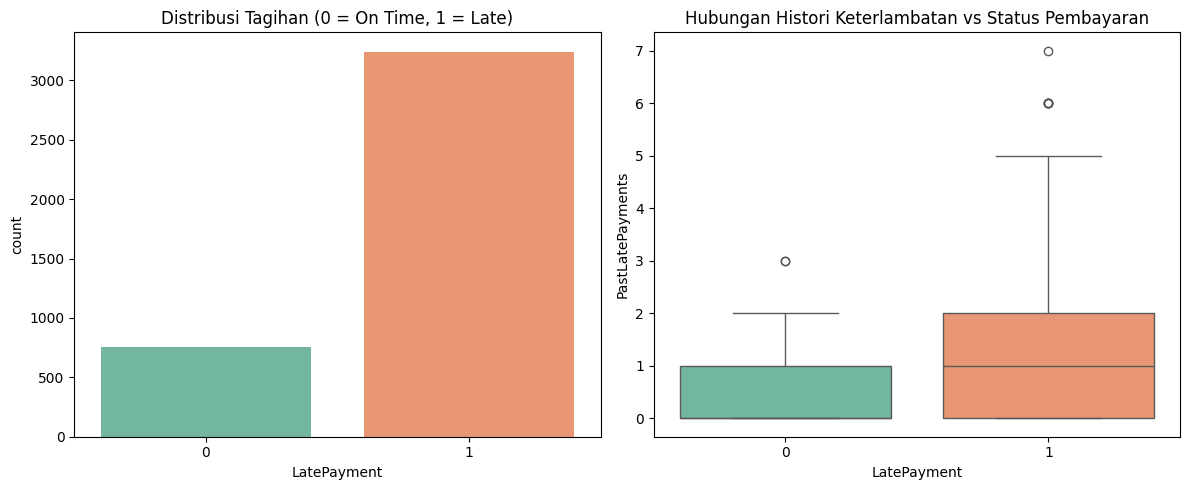

In [8]:
# ==========================================
# 2. EXPLORATORY DATA ANALYSIS (DESCRIPTIVE)
# ==========================================
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.countplot(data=df, x='LatePayment', palette='Set2')
plt.title('Distribusi Tagihan (0 = On Time, 1 = Late)')

plt.subplot(1, 2, 2)
sns.boxplot(data=df, x='LatePayment', y='PastLatePayments', palette='Set2')
plt.title('Hubungan Histori Keterlambatan vs Status Pembayaran')

plt.tight_layout()
plt.show()

In [9]:
# ==========================================
# 3. PREPROCESSING & DATA SPLITTING
# ==========================================
X = df.drop(columns=['LatePayment'])
y = df['LatePayment']

# Split Data (80% Training, 20% Testing)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Scaling Fitur
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [10]:
# ==========================================
# 4. PEMODELAN MACHINE LEARNING (PREDICTIVE)
# ==========================================
models = {
    'Logistic Regression': LogisticRegression(),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42)
}

results = {}

for name, model in models.items():
    # Training
    if name == 'Logistic Regression':
        model.fit(X_train_scaled, y_train)
        y_pred = model.predict(X_test_scaled)
        y_prob = model.predict_proba(X_test_scaled)[:, 1]
    else:
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)
        y_prob = model.predict_proba(X_test)[:, 1]

    # Evaluasi
    roc = roc_auc_score(y_test, y_prob)
    results[name] = {
        'model': model,
        'predictions': y_pred,
        'roc_auc': roc
    }


HASIL EVALUASI MODEL PREDIKSI LATE PAYMENT

--- Logistic Regression (ROC-AUC Score: 0.9974) ---
              precision    recall  f1-score   support

           0       0.95      0.96      0.95       151
           1       0.99      0.99      0.99       649

    accuracy                           0.98       800
   macro avg       0.97      0.97      0.97       800
weighted avg       0.98      0.98      0.98       800


--- Decision Tree (ROC-AUC Score: 0.9403) ---
              precision    recall  f1-score   support

           0       0.91      0.90      0.91       151
           1       0.98      0.98      0.98       649

    accuracy                           0.96       800
   macro avg       0.94      0.94      0.94       800
weighted avg       0.96      0.96      0.96       800


--- Random Forest (ROC-AUC Score: 0.9976) ---
              precision    recall  f1-score   support

           0       0.97      0.93      0.95       151
           1       0.98      0.99      0.99   

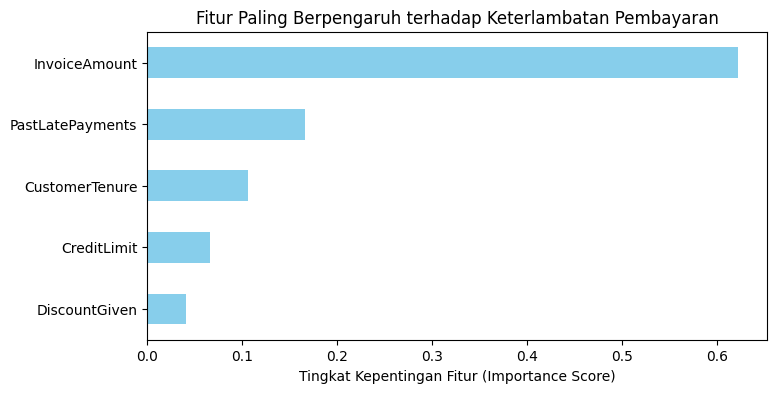

In [11]:
# ==========================================
# 5. EVALUASI MODEL & HASIL
# ==========================================
print("\n" + "="*50)
print("HASIL EVALUASI MODEL PREDIKSI LATE PAYMENT")
print("="*50)

for name, res in results.items():
    print(f"\n--- {name} (ROC-AUC Score: {res['roc_auc']:.4f}) ---")
    print(classification_report(y_test, res['predictions']))

# Feature Importance dari Random Forest (Diagnostic Insight)
rf_model = results['Random Forest']['model']
importances = pd.Series(rf_model.feature_importances_, index=X.columns).sort_values(ascending=False)

plt.figure(figsize=(8, 4))
importances.plot(kind='barh', color='skyblue')
plt.title('Fitur Paling Berpengaruh terhadap Keterlambatan Pembayaran')
plt.xlabel('Tingkat Kepentingan Fitur (Importance Score)')
plt.gca().invert_yaxis()
plt.show()